/var/folders/rl/bm0s3z853m3cgth8g7r8pr6c0000gn/T/ipykernel_59153/1725201566.py:6: DeprecationWarning: numpy.core is deprecated and has been renamed to numpy._core. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.overrides.
  from numpy.core import overrides


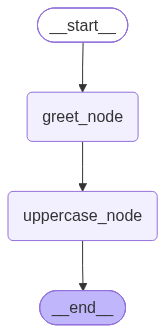

greet_node is receiving name: Alice

uppercase_node is receiving greeting: Hello, Alice!


{'name': 'Alice', 'greeting': 'HELLO, ALICE!'}

In [1]:
from typing import TypedDict

from IPython.core.display import Image
from langgraph.constants import END, START
from langgraph.graph import StateGraph
from rich import print as rich_print


# ===================1. State: 定义共享数据结构=================
class SimpleState(TypedDict):
    name: str  # 记录用户name
    greeting: str  # 记录生成的问候语


# ===================2. Node: 定义处理逻辑===================
# node 1: 生成问候语的节点
def greet_node(state: SimpleState):
    rich_print(f"greet_node is receiving name: {state['name']}")
    return {"greeting": f"Hello, {state['name']}!"}


# node 2: 转大写
def uppercase_node(state: SimpleState):
    print(f"uppercase_node is receiving greeting: {state['greeting']}")
    return {"greeting": state["greeting"].upper()}


# ===================3. 创建Graph===================
builder = StateGraph(SimpleState)  # 3.1.注册State，初始化图Builder
# 3.2.注册节点
builder.add_node(greet_node)
builder.add_node(uppercase_node)
# 3.3.注册Edge，定义Node执行顺序
builder.add_edge(START, "greet_node")
builder.add_edge("greet_node", "uppercase_node")
builder.add_edge("uppercase_node", END)

graph = builder.compile()  # 3.4.编译成可执行图
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

# ===================4.调用graph======================
# 调用graph，传入初始的state，返回的是处理后的 state

# start(用户输入name) --> 节点1（生成问候语）--> 节点2（把问候语转大写）--> end
result = graph.invoke({"name": "Alice"})
rich_print(result)